# LoRA vs LoRA+ Experimental Evaluation

## RoBERTa-base + QQP

### 1. Project Setup and GitHub Integration

Clone the LoRA-Plus project repository from GitHub into Google Colab to utilize GPU resources for model training.

Experiment results are saved in the repository's `results/` directory and can be committed and pushed to GitHub for persistent storage.

In [2]:
from pathlib import Path
import os
import sys
import subprocess

REPO_URL = "https://github.com/Ramprasath-Meganathan/LoRA-Plus.git"
PROJECT_DIR = Path("/content/LoRA-Plus")

if not PROJECT_DIR.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(PROJECT_DIR)],
        check=True
    )
else:
    print("Repository already exists. Using existing files.")

for filename in [
    "config.py",
    "model.py",
    "utils.py",
    "train.py",
    "evaluate_results.py"
]:
    assert (PROJECT_DIR / filename).is_file(), (
        f"Missing project file: {filename}"
    )

os.chdir(PROJECT_DIR)

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

print("Project:", os.getcwd())

Repository already exists. Using existing files.
Project: /content/LoRA-Plus


## 2. Install Required Dependencies

Install the required libraries from the repository's `requirements.txt` file for model fine-tuning, LoRA/LoRA+ optimization, dataset processing, and evaluation.

Remove incompatible `torchao` installations to ensure compatibility with PEFT in Google Colab.

In [3]:
%pip install -r requirements.txt
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 3. Experiment Configuration and GPU Verification

Select RoBERTa-base and the Quora Question Pairs (QQP) dataset.

The experiment uses three training epochs, nine hyperparameter screening configurations, and three random seeds (42, 43, 44) for final evaluation.

Verify that a GPU is available before starting training.

In [4]:
import torch

MODEL_NAME = "roberta"
DATASET_NAME = "qqp"

assert torch.cuda.is_available(), (
    "GPU unavailable. Enable a GPU runtime in Colab."
)

print("Model:", MODEL_NAME)
print("Dataset:", DATASET_NAME)
print("GPU:", torch.cuda.get_device_name(0))

Model: roberta
Dataset: qqp
GPU: NVIDIA L4


## 4. Import Shared Project Modules

Import the reusable configuration, dataset preparation, training, and evaluation functions from the project's Python modules.

These modules provide a consistent experimental pipeline for standard LoRA and LoRA+.

In [5]:
from config import (
    COMMON_CONFIG,
    DATASET_CONFIGS,
    LORA_LEARNING_RATES,
    LORAPLUS_CONFIGS,
    get_output_dir
)

from utils import prepare_dataset, track_compute, detect_gpu
from train import run_experiment

from evaluate_results import (
    select_best,
    summarize_final,
    plot_convergence
)

print("All project modules imported successfully!")
print("Results directory:", get_output_dir(MODEL_NAME, DATASET_NAME))
print("Current GPU:", detect_gpu())

assert COMMON_CONFIG["epochs"] == 3
assert COMMON_CONFIG["seeds"] == [42, 43, 44]
assert DATASET_CONFIGS["qqp"]["primary_metric"] == "f1"

All project modules imported successfully!
Results directory: /content/LoRA-Plus/results/roberta/qqp
Current GPU: L4


## 5. QQP Dataset Loading and Tokenization

Load the GLUE Quora Question Pairs dataset and tokenize both questions using the RoBERTa tokenizer.

Use a fixed 50,000-example training subset and the complete validation split. Prepare the dataset once and reuse it across all training configurations.

In [6]:
with track_compute("50-step sanity test"):

    tokenizer, train_dataset, eval_dataset, data_collator = (
        prepare_dataset(
            model_name=MODEL_NAME,
            dataset_name=DATASET_NAME,
            pilot=False
        )
    )

print("Training examples:", len(train_dataset))
print("Validation examples:", len(eval_dataset))

assert len(train_dataset) == 50000
assert len(eval_dataset) == 40430


⚡ Starting: 50-step sanity test
   Detected GPU: L4
   Assumed Rate: 1.71 CU/hour


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (10 outputs left out)

Map:   0%|          | 0/363846 [00:00<?, ? examples/s]

Map:   0%|          | 0/40430 [00:00<?, ? examples/s]

Map:   0%|          | 0/390965 [00:00<?, ? examples/s]

Model: roberta
Dataset: qqp
Training examples: 50000
Validation examples: 40430

🏁 Experiment Finished: 50-step sanity test
   Hardware: L4
   Execution time: 0.72 minutes (43.36s)
   Peak VRAM Allocated: 0.00 MB
   Estimated Compute Cost: 0.0206 CU (~$0.002)

Training examples: 50000
Validation examples: 40430


## 6. Training Pipeline Sanity Test

Run a short 50-step LoRA+ training experiment to verify model initialization, adapter configuration, optimizer learning rates, GPU execution, and validation metrics.

This sanity test is excluded from the official screening and final experiment results.

In [7]:
with track_compute("50-step sanity test"):

    test = run_experiment(
        model_name=MODEL_NAME,
        dataset_name=DATASET_NAME,
        tokenizer=tokenizer,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        data_collator=data_collator,
        lam=4,
        seed=42,
        epochs=3,
        base_lr=1e-4,
        stage="test",
        max_steps=50
    )

print("Training steps:", test["total_steps"])
print("Validation accuracy:", test["final_acc"])
print("Validation binary F1:", test["final_f1"])

assert test["total_steps"] == 50


⚡ Starting: 50-step sanity test
   Detected GPU: L4
   Assumed Rate: 1.71 CU/hour


model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0001
B 147456 0.0004
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
50,0.662552,0.655787,0.631833,0.000000,0.387192


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.662552,0.655787,50,0.631833,0.000000,0.387192



🏁 Experiment Finished: 50-step sanity test
   Hardware: L4
   Execution time: 1.13 minutes (67.88s)
   Peak VRAM Allocated: 1945.02 MB
   Estimated Compute Cost: 0.0322 CU (~$0.003)

Training steps: 50
Validation accuracy: 0.6318327974276527
Validation binary F1: 0.0


## 7. Standard LoRA Hyperparameter Screening

Evaluate standard LoRA using three learning rates: 1e-4, 2e-4, and 4e-4.

Both adapter matrices A and B use equal learning rates. Each configuration is trained for three epochs using random seed 42.

In [8]:
for lr in LORA_LEARNING_RATES:

    with track_compute(f"LoRA LR={lr}"):

        print(f"\nRunning standard LoRA: LR={lr}")

        run_experiment(
            model_name=MODEL_NAME,
            dataset_name=DATASET_NAME,
            tokenizer=tokenizer,
            train_dataset=train_dataset,
            eval_dataset=eval_dataset,
            data_collator=data_collator,
            lam=1,
            seed=COMMON_CONFIG["screening_seed"],
            epochs=COMMON_CONFIG["epochs"],
            base_lr=lr,
            stage="screening"
        )


⚡ Starting: LoRA LR=0.0001
   Detected GPU: L4
   Assumed Rate: 1.71 CU/hour

Running standard LoRA: LR=0.0001


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0001
B 147456 0.0001
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.566228,0.514022,0.713950,0.675987,0.709969
400,0.473405,0.442297,0.787287,0.742422,0.780632
600,0.432176,0.407188,0.806975,0.761710,0.799749
800,0.425842,0.392430,0.814865,0.765632,0.806318
1000,0.405533,0.405465,0.806282,0.772087,0.801821
1200,0.400461,0.376219,0.823893,0.772509,0.814425
1400,0.425808,0.369872,0.826812,0.774478,0.816955
1600,0.403395,0.373185,0.823250,0.780407,0.816256
1800,0.397035,0.391623,0.814890,0.782594,0.810713
2000,0.380696,0.367421,0.829137,0.772793,0.817941


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.352215,0.350977,4689,0.837447,0.792498,0.829444


... (9 outputs left out)

trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0004
B 147456 0.0004
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.432906,0.437841,0.785333,0.756174,0.782218
400,0.416633,0.420055,0.793544,0.764162,0.790289
600,0.389636,0.381318,0.817165,0.783162,0.812556
800,0.399744,0.359496,0.832525,0.791205,0.825699
1000,0.366350,0.380915,0.822929,0.791738,0.818866
1200,0.367201,0.357074,0.840514,0.798513,0.833269
1400,0.389957,0.345634,0.843483,0.800202,0.835776
1600,0.354584,0.347031,0.842543,0.801398,0.835481
1800,0.348984,0.373331,0.833292,0.802554,0.829152
2000,0.352311,0.352793,0.840292,0.776210,0.826027


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.311444,0.321272,4689,0.857284,0.814458,0.849253


Saved result: /content/LoRA-Plus/results/roberta/qqp/runs/roberta_qqp_lam1_lr0.0004_seed42_ep3_bs32_steps-1_screening.json

🏁 Experiment Finished: LoRA LR=0.0004
   Hardware: L4
   Execution time: 16.97 minutes (1017.99s)
   Peak VRAM Allocated: 1946.52 MB
   Estimated Compute Cost: 0.4835 CU (~$0.048)



## 8A. LoRA+ Hyperparameter Screening - Batch 1

Evaluate the first two LoRA+ configurations using a base learning rate of 1e-4 and learning-rate ratios of 4× and 8×.

Each configuration is trained for three epochs using random seed 42.

In [9]:
# LoRA+ Screening — Batch 1
# Configurations 1 and 2

for lr, ratio in LORAPLUS_CONFIGS[0:2]:

    with track_compute(f"LoRA+ LR={lr}, ratio={ratio}"):

        print(f"\nRunning LoRA+: A LR={lr}, B LR={lr * ratio}, Ratio={ratio}")

        run_experiment(
            model_name=MODEL_NAME,
            dataset_name=DATASET_NAME,
            tokenizer=tokenizer,
            train_dataset=train_dataset,
            eval_dataset=eval_dataset,
            data_collator=data_collator,
            lam=ratio,
            seed=COMMON_CONFIG["screening_seed"],
            epochs=COMMON_CONFIG["epochs"],
            base_lr=lr,
            stage="screening"
        )

print("Batch 1 completed!")


⚡ Starting: LoRA+ LR=0.0001, ratio=4
   Detected GPU: L4
   Assumed Rate: 1.71 CU/hour

Running LoRA+: A LR=0.0001, B LR=0.0004, Ratio=4


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0001
B 147456 0.0004
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.482840,0.441291,0.778333,0.725261,0.769741
400,0.439332,0.421951,0.795647,0.758534,0.790703
600,0.409785,0.396874,0.809374,0.775417,0.804914
800,0.412449,0.370510,0.827158,0.780141,0.818875
1000,0.392279,0.393571,0.811947,0.781943,0.808318
1200,0.383674,0.356950,0.835370,0.785055,0.825826
1400,0.407450,0.356840,0.835716,0.782643,0.825300
1600,0.378080,0.357504,0.833218,0.792248,0.826469
1800,0.375643,0.394974,0.818872,0.789961,0.815374
2000,0.362762,0.354958,0.839302,0.781415,0.827182


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.337727,0.334704,4689,0.848256,0.805331,0.840501


... (4 outputs left out)

Step,Training Loss,Validation Loss


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.490407,0.466429,0.772298,0.730346,0.766650
400,0.441415,0.450723,0.770393,0.749589,0.768797
600,0.414573,0.395375,0.813950,0.775355,0.808292
800,0.407446,0.379800,0.822830,0.781302,0.816203
1000,0.393643,0.398109,0.811229,0.782192,0.807813
1200,0.390966,0.356414,0.835469,0.790620,0.827557
1400,0.405912,0.370340,0.834306,0.792684,0.827347
1600,0.375064,0.362789,0.835617,0.797378,0.829546
1800,0.358210,0.402194,0.826861,0.796984,0.823028
2000,0.382604,0.352421,0.840564,0.779880,0.827450


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.333968,0.329605,4689,0.851546,0.810603,0.844268


Saved result: /content/LoRA-Plus/results/roberta/qqp/runs/roberta_qqp_lam8_lr0.0001_seed42_ep3_bs32_steps-1_screening.json

🏁 Experiment Finished: LoRA+ LR=0.0001, ratio=8
   Hardware: L4
   Execution time: 16.97 minutes (1018.04s)
   Peak VRAM Allocated: 1946.52 MB
   Estimated Compute Cost: 0.4836 CU (~$0.048)

Batch 1 completed!


## 8B. LoRA+ Hyperparameter Screening - Batch 2

Evaluate the next two LoRA+ configurations using a base learning rate of 1e-4 with a ratio of 16× and a base learning rate of 2e-4 with a ratio of 4×.

Each configuration is trained for three epochs using random seed 42.

In [11]:
# LoRA+ Screening — Batch 2
# Configurations 3 and 4

for lr, ratio in LORAPLUS_CONFIGS[2:4]:

    with track_compute(f"LoRA+ LR={lr}, ratio={ratio}"):

        print(f"\nRunning LoRA+: A LR={lr}, B LR={lr * ratio}, Ratio={ratio}")

        run_experiment(
            model_name=MODEL_NAME,
            dataset_name=DATASET_NAME,
            tokenizer=tokenizer,
            train_dataset=train_dataset,
            eval_dataset=eval_dataset,
            data_collator=data_collator,
            lam=ratio,
            seed=COMMON_CONFIG["screening_seed"],
            epochs=COMMON_CONFIG["epochs"],
            base_lr=lr,
            stage="screening"
        )

print("Batch 2 completed!")


⚡ Starting: LoRA+ LR=0.0001, ratio=16
   Detected GPU: L4
   Assumed Rate: 1.71 CU/hour

Running LoRA+: A LR=0.0001, B LR=0.0016, Ratio=16


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0001
B 147456 0.0016
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.455983,0.433634,0.792877,0.748770,0.786290
400,0.442972,0.424596,0.796389,0.767589,0.793213
600,0.389525,0.401822,0.807816,0.778683,0.804427
800,0.406568,0.364272,0.832229,0.788619,0.824770
1000,0.388038,0.368685,0.830843,0.795808,0.825712
1200,0.371290,0.354581,0.841875,0.791072,0.831938
1400,0.398662,0.359773,0.841900,0.800674,0.834834
1600,0.360713,0.349524,0.840539,0.801270,0.834060
1800,0.346019,0.380368,0.833070,0.802447,0.828960
2000,0.355144,0.341700,0.845437,0.789914,0.833830


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.316631,0.319968,4689,0.856616,0.813439,0.848502


... (4 outputs left out)

Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.430032,0.466409,0.766733,0.744812,0.764999
400,0.422211,0.405344,0.802548,0.770873,0.798701
600,0.389871,0.379023,0.822261,0.784062,0.816519
800,0.402924,0.361942,0.832229,0.788078,0.824616
1000,0.371852,0.377313,0.822261,0.790837,0.818156
1200,0.370913,0.363092,0.840688,0.798976,0.833520
1400,0.392106,0.348763,0.844868,0.797206,0.835798
1600,0.358335,0.347638,0.842889,0.801363,0.835709
1800,0.348667,0.377954,0.838189,0.806381,0.833701
2000,0.347876,0.345191,0.843458,0.784633,0.830837


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.430032,0.466409,0.766733,0.744812,0.764999
400,0.422211,0.405344,0.802548,0.770873,0.798701
600,0.389871,0.379023,0.822261,0.784062,0.816519
800,0.402924,0.361942,0.832229,0.788078,0.824616
1000,0.371852,0.377313,0.822261,0.790837,0.818156
1200,0.370913,0.363092,0.840688,0.798976,0.833520
1400,0.392106,0.348763,0.844868,0.797206,0.835798
1600,0.358335,0.347638,0.842889,0.801363,0.835709
1800,0.348667,0.377954,0.838189,0.806381,0.833701
2000,0.347876,0.345191,0.843458,0.784633,0.830837


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.313090,0.321227,4689,0.857086,0.813276,0.848761


Saved result: /content/LoRA-Plus/results/roberta/qqp/runs/roberta_qqp_lam4_lr0.0002_seed42_ep3_bs32_steps-1_screening.json

🏁 Experiment Finished: LoRA+ LR=0.0002, ratio=4
   Hardware: L4
   Execution time: 17.17 minutes (1030.12s)
   Peak VRAM Allocated: 1946.52 MB
   Estimated Compute Cost: 0.4893 CU (~$0.049)

Batch 2 completed!


## 8C. LoRA+ Hyperparameter Screening - Batch 3

Evaluate the final two LoRA+ configurations using a base learning rate of 2e-4 and learning-rate ratios of 8× and 16×.

Each configuration is trained for three epochs using random seed 42.

In [10]:
# LoRA+ Screening — Batch 3
# Configurations 5 and 6

for lr, ratio in LORAPLUS_CONFIGS[4:6]:

     with track_compute(f"LoRA+ LR={lr}, ratio={ratio}"):

        print(f"\nRunning LoRA+: A LR={lr}, B LR={lr * ratio}, Ratio={ratio}")

        run_experiment(
            model_name=MODEL_NAME,
            dataset_name=DATASET_NAME,
            tokenizer=tokenizer,
            train_dataset=train_dataset,
            eval_dataset=eval_dataset,
            data_collator=data_collator,
            lam=ratio,
            seed=COMMON_CONFIG["screening_seed"],
            epochs=COMMON_CONFIG["epochs"],
            base_lr=lr,
            stage="screening"
        )

print("Batch 3 completed!")


⚡ Starting: LoRA+ LR=0.0002, ratio=8
   Detected GPU: L4
   Assumed Rate: 1.71 CU/hour

Running LoRA+: A LR=0.0002, B LR=0.0016, Ratio=8


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0002
B 147456 0.0016
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.435908,0.434775,0.788400,0.759644,0.785327
400,0.423581,0.430545,0.784566,0.761043,0.782458
600,0.394706,0.396351,0.810636,0.782005,0.807312
800,0.399712,0.362399,0.834529,0.782056,0.824347
1000,0.378259,0.371242,0.825600,0.795428,0.821722
1200,0.369253,0.362247,0.840465,0.802050,0.834222
1400,0.395301,0.368051,0.832698,0.801316,0.828418
1600,0.349167,0.343349,0.844447,0.797996,0.835763
1800,0.338757,0.389230,0.830670,0.801967,0.827037
2000,0.344145,0.339330,0.848454,0.791151,0.836117


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.299113,0.315028,4689,0.862157,0.818911,0.853820


... (3 outputs left out)

trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0002
B 147456 0.0032
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.480160,0.497289,0.761934,0.734182,0.759311
400,0.445560,0.408809,0.799926,0.766854,0.795817
600,0.411461,0.406509,0.807890,0.778863,0.804522
800,0.406063,0.360932,0.835568,0.783481,0.825467
1000,0.385785,0.380154,0.822088,0.792116,0.818311
1200,0.367047,0.377492,0.840811,0.798371,0.833431
1400,0.395890,0.367441,0.835172,0.799952,0.829899
1600,0.350652,0.336352,0.849023,0.800861,0.839644
1800,0.338499,0.411132,0.833119,0.803655,0.829274
2000,0.344131,0.341160,0.847811,0.801702,0.839112


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.293470,0.320442,4689,0.862775,0.821963,0.855164


Saved result: /content/LoRA-Plus/results/roberta/qqp/runs/roberta_qqp_lam16_lr0.0002_seed42_ep3_bs32_steps-1_screening.json

🏁 Experiment Finished: LoRA+ LR=0.0002, ratio=16
   Hardware: L4
   Execution time: 17.05 minutes (1023.29s)
   Peak VRAM Allocated: 1946.52 MB
   Estimated Compute Cost: 0.4861 CU (~$0.049)

Batch 3 completed!


## 9. Best Hyperparameter Selection

Select the best-performing standard LoRA and LoRA+ configurations based on final validation binary F1 after three epochs.

Validation loss is used as a tie-breaker when configurations achieve identical F1 scores.

In [12]:
best_lora, best_loraplus = select_best(
    MODEL_NAME,
    DATASET_NAME
)

BEST_LORA_LR = float(best_lora["eta_A"])
BEST_LORAPLUS_LR = float(best_loraplus["eta_A"])
BEST_LAM = int(best_loraplus["lam"])

print("\nSelected standard LoRA:")
print("A LR:", BEST_LORA_LR)
print("B LR:", BEST_LORA_LR)

print("\nSelected LoRA+:")
print("A LR:", BEST_LORAPLUS_LR)
print("B LR:", BEST_LORAPLUS_LR * BEST_LAM)
print("Ratio:", BEST_LAM)


Best standard LoRA:
eta_A         0.0004
eta_B         0.0004
final_f1    0.814458
Name: 2, dtype: object

Best LoRA+:
eta_A         0.0002
eta_B         0.0032
lam               16
final_f1    0.821963
Name: 6, dtype: object

Selected standard LoRA:
A LR: 0.0004
B LR: 0.0004

Selected LoRA+:
A LR: 0.0002
B LR: 0.0032
Ratio: 16


## 10. Final Multi-Seed Experiments

Evaluate the selected standard LoRA and LoRA+ configurations across three random seeds: 42, 43, and 44.

Each run initializes a fresh pretrained model and trains for three epochs using the same dataset and experimental settings.

In [14]:
for seed in COMMON_CONFIG["seeds"]:

    with track_compute(f"Final LoRA seed={seed}"):


        print(f"\nFinal LoRA run — seed {seed}")

        run_experiment(
            model_name=MODEL_NAME,
            dataset_name=DATASET_NAME,
            tokenizer=tokenizer,
            train_dataset=train_dataset,
            eval_dataset=eval_dataset,
            data_collator=data_collator,
            lam=1,
            seed=seed,
            epochs=COMMON_CONFIG["epochs"],
            base_lr=BEST_LORA_LR,
            stage="final"
        )

    with track_compute(f"Final LoRA+ seed={seed}"):

        print(f"\nFinal LoRA+ run — seed {seed}")

        run_experiment(
            model_name=MODEL_NAME,
            dataset_name=DATASET_NAME,
            tokenizer=tokenizer,
            train_dataset=train_dataset,
            eval_dataset=eval_dataset,
            data_collator=data_collator,
            lam=BEST_LAM,
            seed=seed,
            epochs=COMMON_CONFIG["epochs"],
            base_lr=BEST_LORAPLUS_LR,
            stage="final"
        )


⚡ Starting: Final LoRA seed=42
   Detected GPU: L4
   Assumed Rate: 1.71 CU/hour

Final LoRA run — seed 42


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0004
B 147456 0.0004
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.432906,0.437841,0.785333,0.756174,0.782218
400,0.416633,0.420055,0.793544,0.764162,0.790289
600,0.389636,0.381318,0.817165,0.783162,0.812556
800,0.399744,0.359496,0.832525,0.791205,0.825699
1000,0.366350,0.380915,0.822929,0.791738,0.818866
1200,0.367201,0.357074,0.840514,0.798513,0.833269
1400,0.389957,0.345634,0.843483,0.800202,0.835776
1600,0.354584,0.347031,0.842543,0.801398,0.835481
1800,0.348984,0.373331,0.833292,0.802554,0.829152
2000,0.352311,0.352793,0.840292,0.776210,0.826027


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.311444,0.321272,4689,0.857284,0.814458,0.849253


... (28 outputs left out)

Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.504803,0.415257,0.802053,0.748135,0.792546
400,0.434068,0.431613,0.791269,0.766058,0.788816


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.504803,0.415257,0.802053,0.748135,0.792546
400,0.434068,0.431613,0.791269,0.766058,0.788816
600,0.381092,0.370980,0.828494,0.764885,0.814949
800,0.347102,0.407509,0.827851,0.796919,0.823762
1000,0.362204,0.353368,0.833292,0.795720,0.827455
1200,0.371321,0.343809,0.849345,0.798291,0.839033
1400,0.381244,0.333955,0.847094,0.804516,0.839479
1600,0.350980,0.326543,0.850754,0.803989,0.841746
1800,0.320674,0.346148,0.848405,0.808535,0.841533
2000,0.338024,0.324118,0.852708,0.810549,0.845034


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.274658,0.310819,4689,0.863171,0.821939,0.855418


Saved result: /content/LoRA-Plus/results/roberta/qqp/runs/roberta_qqp_lam16_lr0.0002_seed44_ep3_bs32_steps-1_final.json

🏁 Experiment Finished: Final LoRA+ seed=44
   Hardware: L4
   Execution time: 17.07 minutes (1024.46s)
   Peak VRAM Allocated: 2971.04 MB
   Estimated Compute Cost: 0.4866 CU (~$0.049)



## 11. Final Performance Summary

Aggregate the final experimental results across three random seeds.

Report mean and standard deviation for validation accuracy, binary F1, macro-F1, validation loss, training runtime, GPU memory usage, and trainable parameter count.

In [15]:
summary = summarize_final(
    MODEL_NAME,
    DATASET_NAME
)

display(summary)


Best standard LoRA:
eta_A         0.0004
eta_B         0.0004
final_f1    0.814458
Name: 2, dtype: object

Best LoRA+:
eta_A         0.0002
eta_B         0.0032
lam               16
final_f1    0.821963
Name: 6, dtype: object

Final results:
                  final_acc            final_f1           final_f1_macro           final_eval_loss           train_runtime_s           peak_mem_gb           trainable_params     
                       mean       std      mean       std           mean       std            mean       std            mean       std        mean       std             mean  std
method lam eta_A                                                                                                                                                                  
LoRA   1   0.0004  0.857317  0.001311  0.815367  0.000969       0.849548  0.001073        0.320535  0.000831      987.212633  4.325780     3.11571  0.002119         887042.0  0.0
LoRA+  16  0.0002  0.863361  0.000700  0.

final_acc            final_f1           final_f1_macro  \
                       mean       std      mean       std           mean   
method lam eta_A                                                           
LoRA   1   0.0004  0.857317  0.001311  0.815367  0.000969       0.849548   
LoRA+  16  0.0002  0.863361  0.000700  0.822215  0.000458       0.855627   

                            final_eval_loss           train_runtime_s  \
                        std            mean       std            mean   
method lam eta_A                                                        
LoRA   1   0.0004  0.001073        0.320535  0.000831      987.212633   
LoRA+  16  0.0002  0.000596        0.313139  0.006463      990.572400   

                            peak_mem_gb           trainable_params       
                        std        mean       std             mean  std  
method lam eta_A                                                         
LoRA   1   0.0004  4.325780     3.11571  0.002119         887042.0  0.0  
LoRA+  16  0.0002  3.639592     3.11571  0.002119         887042.0  0.0

## 12. Convergence Analysis

Compare the convergence behavior of standard LoRA and LoRA+ using validation binary F1 against optimizer steps.

Plot the mean performance across three random seeds with standard-deviation bands to analyze training efficiency and convergence stability.


Best standard LoRA:
eta_A         0.0004
eta_B         0.0004
final_f1    0.814458
Name: 2, dtype: object

Best LoRA+:
eta_A         0.0002
eta_B         0.0032
lam               16
final_f1    0.821963
Name: 6, dtype: object


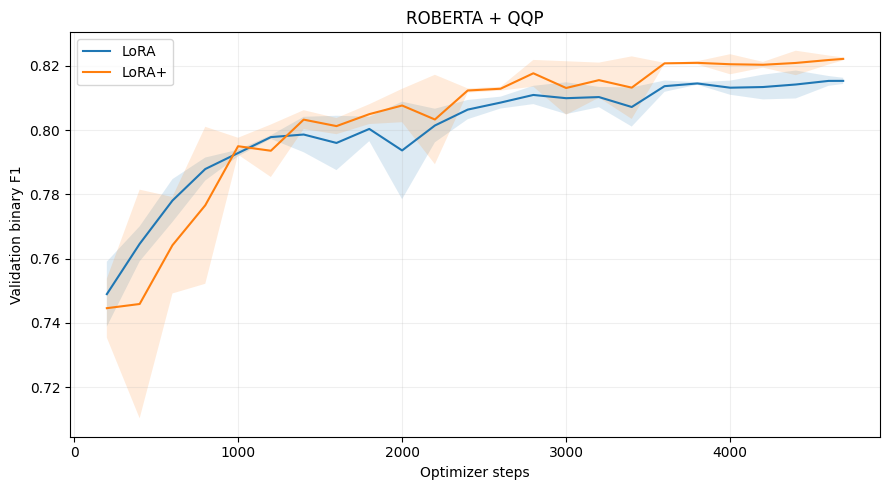

Saved: /content/LoRA-Plus/results/roberta/qqp/convergence.png


In [16]:
plot_convergence(
    MODEL_NAME,
    DATASET_NAME
)

# Download the results as zip


In [17]:
from pathlib import Path
from google.colab import files
import zipfile

# Automatically select SST-2 or QQP
root = get_output_dir(MODEL_NAME, DATASET_NAME)

assert root.exists(), "Results directory does not exist"

# Create ZIP file outside the results directory
zip_path = Path(
    f"/content/{MODEL_NAME}_{DATASET_NAME}_results.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for path in root.rglob("*"):

        if path.is_file() and "checkpoints" not in path.parts:
            zipf.write(
                path,
                arcname=path.relative_to(root)
            )

print("Backup created:", zip_path)
print("Size:", round(zip_path.stat().st_size / 1024**2, 2), "MB")

# Download ZIP to your laptop
files.download(str(zip_path))

Backup created: /content/roberta_qqp_results.zip
Size: 0.17 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Save Experiment Results to GitHub

Verify, commit, and push completed experiment results to GitHub for persistent storage. Exclude model checkpoints from version control.

In [ ]:
# Cell 13 — Verify, Commit, and Push Results to GitHub

import os
import subprocess
import tempfile
from pathlib import Path
from google.colab import userdata

PROJECT_DIR = Path("/content/LoRA-Plus")
root = get_output_dir(MODEL_NAME, DATASET_NAME)

# 1. Verify results
assert root.exists(), "Results directory not found"
assert (PROJECT_DIR / ".git").exists(), "Git repository not found"

print("Results directory:", root)

for path in sorted(root.rglob("*")):
    if path.is_file() and "checkpoints" not in path.parts:
        print(path.relative_to(root))

# 2. Configure Git identity
subprocess.run(
    ["git", "config", "user.name", "Ramprasath-Meganathan"],
    cwd=PROJECT_DIR,
    check=True
)

subprocess.run(
    ["git", "config", "user.email", "ramprasathmeganathan@gmail.com"],
    cwd=PROJECT_DIR,
    check=True
)

# 3. Stage results, excluding checkpoints
results_path = root.relative_to(PROJECT_DIR).as_posix()

subprocess.run(
    [
        "git", "add", "--all", "--",
        results_path,
        f":(exclude){results_path}/checkpoints/**"
    ],
    cwd=PROJECT_DIR,
    check=True
)

# 4. Commit only if changes exist
status = subprocess.run(
    ["git", "diff", "--cached", "--quiet"],
    cwd=PROJECT_DIR
)

if status.returncode == 1:
    subprocess.run(
        ["git", "commit", "-m",
         f"Save {MODEL_NAME} {DATASET_NAME} experiment results"],
        cwd=PROJECT_DIR,
        check=True
    )
elif status.returncode == 0:
    print("No new changes to commit.")
else:
    raise RuntimeError("Git status check failed")

# 5. Authenticate using Colab Secrets
token = userdata.get("GITHUB_TOKEN")

if not token:
    raise ValueError("GITHUB_TOKEN missing from Colab Secrets")

# 6. Push securely to GitHub
with tempfile.TemporaryDirectory() as temp_dir:

    askpass = Path(temp_dir) / "askpass.sh"

    askpass.write_text(
        '#!/bin/sh\n'
        'case "$1" in\n'
        '  *Username*) echo "x-access-token" ;;\n'
        '  *Password*) printf "%s\\n" "$GITHUB_TOKEN" ;;\n'
        'esac\n'
    )

    askpass.chmod(0o700)

    env = os.environ.copy()
    env["GITHUB_TOKEN"] = token
    env["GIT_ASKPASS"] = str(askpass)
    env["GIT_TERMINAL_PROMPT"] = "0"

    subprocess.run(
        ["git", "push", "origin", "HEAD"],
        cwd=PROJECT_DIR,
        env=env,
        check=True
    )

print("Results successfully pushed to GitHub!")